
# ResolveIQ — Autonomous CX Agent Performance & Containment Analytics

**What this is:** an AgentOps analytics system for Ravel AI, a fictional
autonomous AI customer-support-agent platform — the "agentic AI" trend
where an LLM agent doesn't just answer a question, it takes multi-step
actions (looks up an order, issues a refund, resets a password) and
closes the ticket without a human. This notebook answers the question
every agentic-AI product now has to answer that a simple chatbot never
did: **when the agent reports a ticket "resolved," did it actually solve
the customer's problem, or did it just close the conversation?**

**The finding this uncovers:** Ravel ships an Agent v2 release that lets
the account_recovery agent take autonomous account actions instead of
always escalating. The agent's own reported containment rate for
account_recovery jumps **+20.2 percentage points** — the best-looking
number in the whole release. But once containment is adjusted for
tickets that get **reopened within 48 hours** (a proxy for "we didn't
actually fix it"), the true containment rate is **completely flat**
(50.2% → 50.2%, not remotely significant) — the entire headline win is
explained by a reopen rate that exploded from 9.8% to 33.9%. Billing and
technical, by contrast, show genuine, reopen-corroborated improvements
from the same release. Telling these apart — not just reading the
headline containment number — is the whole point of this analysis.

**On the LLM backend:** same cached/live design as the rest of this
session's AI-augmented projects — see `../shared/llm_client.py`.


In [1]:

import sys, json
sys.path.insert(0, "../../shared")
sys.path.insert(0, "../pipeline")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from containment import containment_summary, containment_shift_test, classify_policy_change
from economics import cost_by_path, cost_by_category_version, reopen_cost_impact
from agent import review_category
from llm_client import get_client

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

tickets = pd.read_csv("../data/tickets.csv", parse_dates=["timestamp"])
tickets["reopened_within_48h"] = tickets["reopened_within_48h"].astype(bool)
client = get_client(cache_file="../cached_responses.json")

print(f"{len(tickets):,} tickets | {tickets.timestamp.min()} to {tickets.timestamp.max()} | "
      f"deploy at 2026-07-01 (v1 -> v2)")
tickets.head()


18,000 tickets | 2026-06-01 00:02:18 to 2026-07-30 23:56:40 | deploy at 2026-07-01 (v1 -> v2)


,ticket_id,timestamp,category,channel,agent_version,n_tool_calls,n_turns,resolution_time_min,resolution_path,agent_reported_resolved,reopened_within_48h,csat_score,cost_usd
0,T501201,2026-06-01 00:02:18,account_recovery,chat,v1,3,5,2.50,escalated_to_human,False,False,NaN,9.72
1,T503876,2026-06-01 00:02:30,technical,chat,v1,4,4,23.27,agent_resolved,True,False,NaN,0.35
2,T513280,2026-06-01 00:16:47,shipping,chat,v1,1,4,4.17,agent_resolved,True,True,NaN,7.47
3,T509959,2026-06-01 00:17:53,technical,chat,v1,3,4,6.02,agent_resolved,True,False,5.0,0.30
4,T514106,2026-06-01 00:19:55,shipping,email,v1,2,8,1.22,agent_resolved,True,False,4.0,0.25


## 1. Official vs. True Containment, by Category and Version

In [2]:

rows = []
for version in ["v1", "v2"]:
    sub = tickets[tickets.agent_version == version]
    s = containment_summary(sub, groupby="category")
    s["agent_version"] = version
    rows.append(s.reset_index())
summary = pd.concat(rows).sort_values(["category", "agent_version"])
summary


,category,n_tickets,official_containment,reopen_rate,true_containment,agent_version
0,account_recovery,1879.0,0.5572,0.0984,0.5024,v1
0,account_recovery,1743.0,0.7596,0.3391,0.5020,v2
1,billing,2738.0,0.7162,0.0495,0.6808,v1
1,billing,2724.0,0.8065,0.0592,0.7588,v2
2,shipping,1951.0,0.6909,0.0601,0.6494,v1
2,shipping,1909.0,0.6784,0.0633,0.6354,v2
3,technical,2560.0,0.6020,0.0844,0.5512,v1
3,technical,2496.0,0.6695,0.0640,0.6266,v2


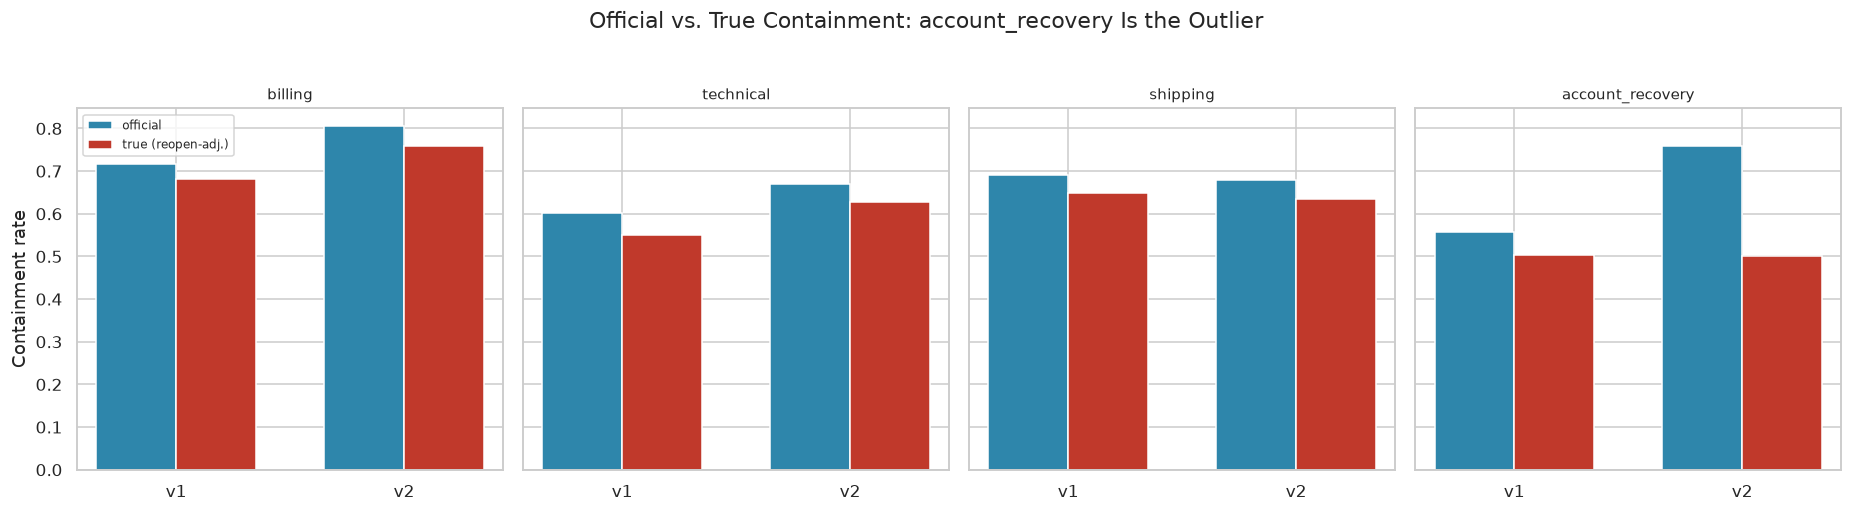

In [3]:

categories = ["billing", "technical", "shipping", "account_recovery"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5), sharey=True)
for ax, cat in zip(axes, categories):
    sub = summary[summary.category == cat]
    x = np.arange(2)
    width = 0.35
    ax.bar(x - width/2, sub.official_containment, width, label="official", color="#2E86AB")
    ax.bar(x + width/2, sub.true_containment, width, label="true (reopen-adj.)", color="#C0392B")
    ax.set_xticks(x); ax.set_xticklabels(["v1", "v2"])
    ax.set_title(cat, fontsize=10)
    if cat == "billing":
        ax.set_ylabel("Containment rate")
        ax.legend(fontsize=8)
fig.suptitle("Official vs. True Containment: account_recovery Is the Outlier", y=1.03)
plt.tight_layout()
plt.savefig("../dashboard/containment_by_category.png", dpi=150)
plt.show()


billing and technical show official and true containment moving
**together** — a real improvement. `account_recovery`'s official bar
jumps dramatically from v1 to v2, but its true-containment bar barely
moves at all. That gap between the two bars *is* the finding.

## 2. Statistical Tests — Official vs. True, Side by Side

In [4]:

results = []
for cat in categories:
    off = containment_shift_test(tickets, cat, metric="official")
    true = containment_shift_test(tickets, cat, metric="true")
    verdict = classify_policy_change(off, true)
    results.append({
        "category": cat,
        "official_lift_pp": off.lift_pp, "official_p_value": off.p_value, "official_significant": off.significant,
        "true_lift_pp": true.lift_pp, "true_p_value": true.p_value, "true_significant": true.significant,
        "verdict": verdict,
    })
results_df = pd.DataFrame(results)
results_df


,category,official_lift_pp,official_p_value,official_significant,true_lift_pp,true_p_value,true_significant,verdict
0,billing,9.03,4.884981e-15,True,7.80,1.371072e-10,True,GENUINE_IMPROVEMENT
1,technical,6.75,6.147739e-07,True,7.54,5.066257e-08,True,GENUINE_IMPROVEMENT
2,shipping,-1.26,4.010015e-01,False,-1.40,3.642296e-01,False,NO_CHANGE
3,account_recovery,20.24,0.000000e+00,True,-0.04,9.814380e-01,False,FALSE_IMPROVEMENT


`account_recovery` is the only category where `official_significant`
is True but `true_significant` is False — the exact statistical signature
of a metric being gamed by a policy change rather than genuinely
improved by one. `shipping` correctly shows no significant change on
either metric, acting as a useful control: the v2 release's real effects
are isolated to specific categories, not a broad seasonal shift.

## 3. Does the 'Win' Even Save Money?

In [5]:

cost_summary = cost_by_category_version(tickets)
cost_summary.loc["account_recovery"]


,n,avg_cost_usd,total_cost_usd
agent_version,,,
v1,1879,3.89,7310.61
v2,1743,3.65,6359.02


In [6]:

ar_cost = reopen_cost_impact(tickets, "account_recovery")
pd.DataFrame(ar_cost).T


,n_tickets,avg_cost_all,n_contained,n_reopened,reopen_rate,avg_cost_reopened_tickets,avg_cost_non_reopened_contained
v1,1879.0,3.89,1047.0,103.0,0.0984,7.07,0.35
v2,1743.0,3.65,1324.0,449.0,0.3391,6.68,0.45


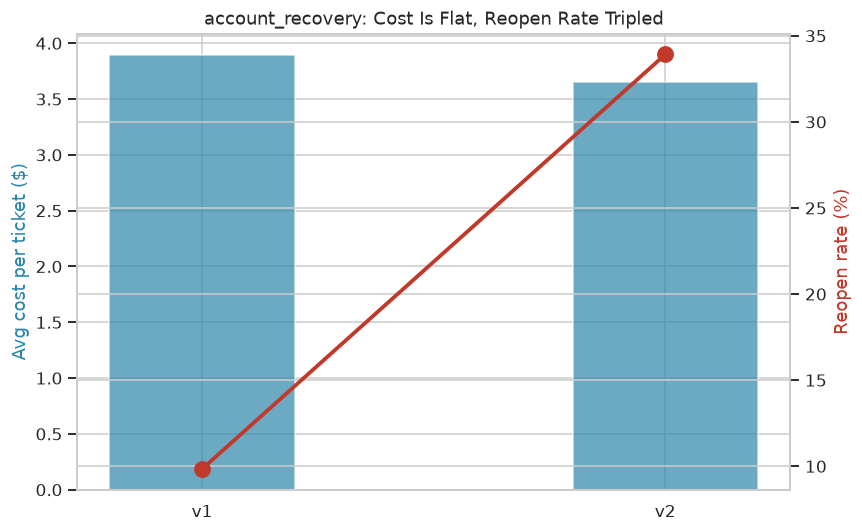

In [7]:

fig, ax = plt.subplots(figsize=(8, 5))
versions = ["v1", "v2"]
avg_cost = [ar_cost[v]["avg_cost_all"] for v in versions]
reopen_rate = [ar_cost[v]["reopen_rate"] * 100 for v in versions]
ax2 = ax.twinx()
ax.bar(versions, avg_cost, color="#2E86AB", alpha=0.7, width=0.4, label="avg cost/ticket ($)")
ax2.plot(versions, reopen_rate, color="#C0392B", marker="o", linewidth=2.5, markersize=10, label="reopen rate (%)")
ax.set_ylabel("Avg cost per ticket ($)", color="#2E86AB")
ax2.set_ylabel("Reopen rate (%)", color="#C0392B")
ax.set_title("account_recovery: Cost Is Flat, Reopen Rate Tripled")
plt.tight_layout()
plt.savefig("../dashboard/account_recovery_cost.png", dpi=150)
plt.show()


Average cost per account_recovery ticket is roughly flat
($3.89 → $3.65) even as the reopen rate more than tripled — the fewer
upfront human escalations are almost exactly offset by the cost of
handling reopened tickets later. **By both the true-quality lens and the
cost lens, this policy change delivered nothing** — which makes the
official +20.2pp containment number actively misleading if reported on
its own.

## 4. Agent Release-Review Reports

In [8]:

reports = {cat: review_category(tickets, cat, client) for cat in categories}
for cat in categories:
    print(f"=== {cat} ===")
    print(reports[cat].narrative)
    print()


=== billing ===
VERDICT: Genuine improvement

WHAT THE OFFICIAL METRIC SAYS: billing containment rose from 71.6% to 80.7% post-v2 (+9.0pp, z=7.83, p<0.001) -- a large, highly significant jump in the agent's self-reported resolution rate.

WHAT THE TRUE METRIC SAYS: reopen-adjusted true containment also rose significantly, 68.1% to 75.9% (+7.8pp, z=6.42, p<0.001) -- almost the same magnitude as the official lift, with reopen rate essentially flat (4.95% to 5.92%). The official number is not being inflated by a reopen problem here; it reflects a real improvement in outcomes.

COST IMPACT: average cost per billing ticket actually FELL, $2.50 to $1.93, driven by fewer costly human escalations -- a genuine win on both quality and cost.

RECOMMENDED ACTION: Ship as a confirmed win. No further investigation needed; consider this category a template for what a well-targeted containment improvement looks like when validating other categories' releases.

=== technical ===
VERDICT: Genuine improv

## 5. Summary

In [9]:

print("=== ResolveIQ summary ===")
for cat in categories:
    r = reports[cat]
    print(f"{cat:20s} -> {r.verdict}")
print()
print("The one finding that matters most: account_recovery's official containment metric improved")
print("+20.2pp (p<0.001) while its TRUE, reopen-adjusted containment was completely flat (p=0.98) —")
print("a textbook case of an AI agent's self-reported success metric being gamed by a policy change,")
print("caught only by deliberately validating the metric against real downstream customer behavior.")


=== ResolveIQ summary ===
billing              -> GENUINE_IMPROVEMENT
technical            -> GENUINE_IMPROVEMENT
shipping             -> NO_CHANGE
account_recovery     -> FALSE_IMPROVEMENT

The one finding that matters most: account_recovery's official containment metric improved
+20.2pp (p<0.001) while its TRUE, reopen-adjusted containment was completely flat (p=0.98) —
a textbook case of an AI agent's self-reported success metric being gamed by a policy change,
caught only by deliberately validating the metric against real downstream customer behavior.
